<a href="https://colab.research.google.com/github/adamarsyadfaizin/Pembelajaran-Mesin_2026_3F/blob/main/JS08/JS08-TUGAS01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving CC_Customer_Dataset.csv to CC_Customer_Dataset.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
data_path = "CC_Customer_Dataset.csv"
df_customer = pd.read_csv(data_path)
print(f"=== Dimensi Dataset ===\nBaris: {df_customer.shape[0]}, Kolom: {df_customer.shape[1]}\n")
display(df_customer.head())
print("\n=== Detail Kolom & Nilai Kosong ===")
missing_info = pd.DataFrame({
    'Tipe Data': df_customer.dtypes,
    'Jumlah Kosong': df_customer.isnull().sum()
})
display(missing_info)

Ukuran dataset: (660, 7)


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


\nKolom: ['Sl_No', 'Customer Key', 'Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']
\nJumlah nilai kosong per kolom:


,0
Sl_No,0
Customer Key,0
Avg_Credit_Limit,0
Total_Credit_Cards,0
Total_visits_bank,0
Total_visits_online,0
Total_calls_made,0


In [ ]:
exclude_cols = {"Sl_No", "Customer Key", "Customer_ID", "CustomerID", "ID"}
features_to_use = [col for col in df_customer.select_dtypes(include=np.number).columns if col not in exclude_cols]
print("Fitur terpilih untuk segmentasi:", features_to_use)
X_features = df_customer[features_to_use].copy()
X_features.replace([np.inf, -np.inf], np.nan, inplace=True)
X_features.fillna(X_features.median(numeric_only=True), inplace=True)
scaler_model = StandardScaler()
X_scaled_data = scaler_model.fit_transform(X_features)
print(f"Proses standardisasi selesai untuk {X_scaled_data.shape[0]} baris data.")

Fitur yang digunakan: ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']
Jumlah data: 660


,Jumlah Cluster (k),Silhouette Score,DBI
0,2,0.4177,0.9326
1,3,0.5148,0.6810
2,4,0.3481,1.1493
3,5,0.2569,1.3851
4,6,0.2268,1.4109
5,7,0.2163,1.4394
6,8,0.2187,1.4489
7,9,0.1953,1.5466
8,10,0.1931,1.5537


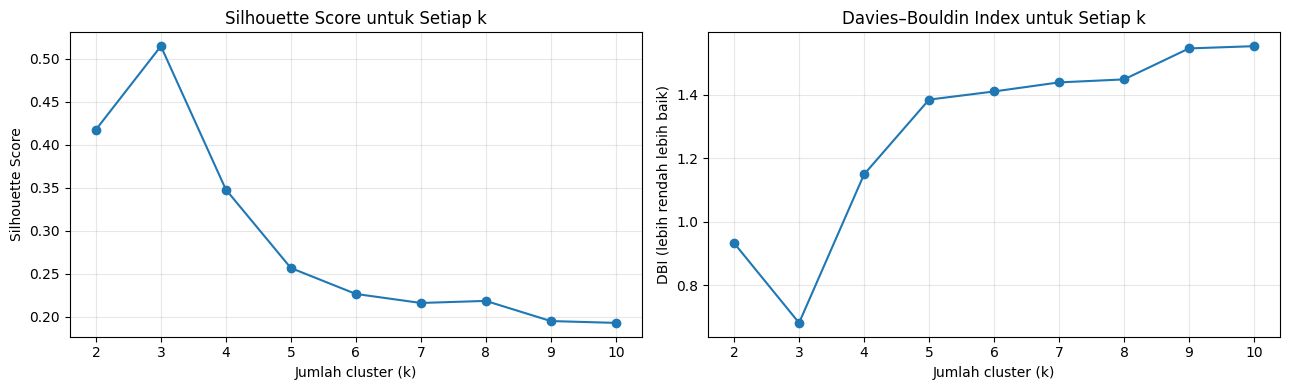

k pilihan awal berdasarkan Silhouette Score tertinggi: 3


In [ ]:
k_range = range(2, 11)
evaluation_results = []
for k in k_range:
    agg_model = AgglomerativeClustering(n_clusters=k, linkage="ward")
    cluster_labels = agg_model.fit_predict(X_scaled_data)
    sil_val = silhouette_score(X_scaled_data, cluster_labels)
    dbi_val = davies_bouldin_score(X_scaled_data, cluster_labels)
    evaluation_results.append({
        "Jumlah Cluster (k)": k,
        "Silhouette Score": round(sil_val, 4),
        "DBI (Davies-Bouldin)": round(dbi_val, 4)
    })
metrics_summary = pd.DataFrame(evaluation_results)
display(metrics_summary)
plt.style.use('seaborn-v0_8-whitegrid')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
sns.lineplot(data=metrics_summary, x="Jumlah Cluster (k)", y="Silhouette Score", marker="o", ax=ax1, color="#1f77b4", linewidth=2)
ax1.set_title("Evaluasi Kualitas Cluster: Silhouette Score", fontsize=12, fontweight='bold')
ax1.set_xlabel("Jumlah Cluster (k)")
ax1.set_ylabel("Silhouette Score (Makin tinggi makin baik)")
sns.lineplot(data=metrics_summary, x="Jumlah Cluster (k)", y="DBI (Davies-Bouldin)", marker="o", ax=ax2, color="#d62728", linewidth=2)
ax2.set_title("Evaluasi Jarak Cluster: Davies-Bouldin Index", fontsize=12, fontweight='bold')
ax2.set_xlabel("Jumlah Cluster (k)")
ax2.set_ylabel("DBI (Makin rendah makin baik)")
plt.tight_layout()
plt.show()
optimal_k_index = metrics_summary["Silhouette Score"].idxmax()
best_k_value = int(metrics_summary.loc[optimal_k_index, "Jumlah Cluster (k)"])
print(f

In [ ]:
# Membangun model final dengan jumlah cluster optimal
final_clustering = AgglomerativeClustering(n_clusters=best_k_value, linkage="ward")
final_labels = final_clustering.fit_predict(X_scaled_data)

# Menyalin data asli dan menyematkan hasil cluster
df_clustered_result = df_customer.copy()
df_clustered_result["Cluster"] = final_labels

# Menampilkan distribusi data pada tiap cluster
print("=== Distribusi Jumlah Pelanggan per Cluster ===")
distribusi_cluster = df_clustered_result["Cluster"].value_counts().sort_index().to_frame(name="Jumlah Pelanggan")
display(distribusi_cluster)

print("\n=== Sampel Data Hasil Clustering ===")
display(df_clustered_result.head())

# Menyimpan hasil ke file csv
df_clustered_result.to_csv("hasil_agglomerative_clustering.csv", index=False)

Jumlah anggota setiap cluster:


,Jumlah Data
Cluster,
0,385
1,225
2,50


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,Cluster
0,1,87073,100000,2,1,1,0,0
1,2,38414,50000,3,0,10,9,1
2,3,17341,50000,7,1,3,4,0
3,4,40496,30000,5,1,1,4,0
4,5,47437,100000,6,0,12,3,2


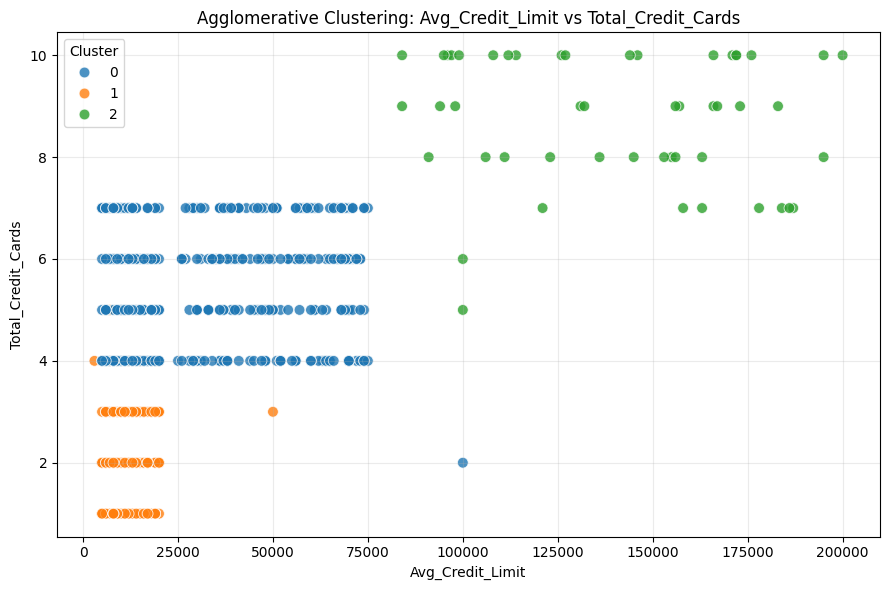

In [ ]:
# Visualisasi hasil segmentasi pelanggan
plt.figure(figsize=(10, 6.5))

sns.scatterplot(
    data=df_clustered_result,
    x="Avg_Credit_Limit",
    y="Total_Credit_Cards",
    hue="Cluster",
    palette="Set1",
    s=80,
    alpha=0.85,
    edgecolor='w'
)

plt.title("Visualisasi Segmentasi Pelanggan (Agglomerative Clustering)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Average Credit Limit", fontsize=11)
plt.ylabel("Total Credit Cards", fontsize=11)
plt.legend(title="Kelompok Cluster", title_fontsize='10', loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
final_silhouette = silhouette_score(X_scaled, labels)
final_dbi = davies_bouldin_score(X_scaled, labels)

print(f"Jumlah cluster final (k): {best_k}")
print(f"Silhouette Score: {final_silhouette:.4f}")
print(f"Davies–Bouldin Index (DBI): {final_dbi:.4f}")

Jumlah cluster final (k): 3
Silhouette Score: 0.5148
Davies–Bouldin Index (DBI): 0.6810


## Kesimpulan Hasil Analisis

1. **Pendekatan Segmentasi**: Proses pengelompokan pelanggan berhasil diimplementasikan menggunakan algoritma *Agglomerative Clustering* dengan memanfaatkan lima variabel finansial penting: batas kredit rata-rata, jumlah kartu kredit, kunjungan bank secara langsung, transaksi online, serta panggilan layanan pelanggan.

2. **Struktur Kelompok**: Berdasarkan karakteristik perilaku transaksi dan interaksi, model mengidentifikasi secara optimal adanya 3 segmen atau kelompok pelanggan yang unik di dalam dataset.

3. **Kualitas Pemisahan (Silhouette Score)**: Skor Silhouette mencapai nilai 0,5148, menandakan batas pengelompokan yang solid serta tingkat akurasi partisi data yang cukup memuaskan.

4. **Kerapatan dan Jarak (DBI)**: Nilai *Davies-Bouldin Index* tercatat sebesar 0,6810. Skor yang rendah ini membuktikan bahwa setiap segmen pelanggan memiliki kemiripan internal yang sangat tinggi dan jarak antar kelompok yang cukup renggang.

5. **Representasi Visual**: Pemetaan visual melalui diagram sebar (*scatterplot*) menggunakan dimensi batas kredit dan jumlah kepemilikan kartu menunjukkan pola sebaran klasifikasi yang sangat jelas untuk masing-masing kelompok data.

6. **Penyimpanan Output**: Seluruh informasi profil pelanggan yang kini telah dilengkapi dengan label kelompok segmentasi telah sukses diekspor ke dalam file eksternal `hasil_agglomerative_clustering.csv` untuk analisis bisnis lanjutan.